In [2]:
import cv2
import numpy as np
import time
import mediapipe as mp
import matplotlib.pyplot as plt

(<Axes: title={'center': 'Маска (Синий)'}>,
 Text(0.5, 1.0, 'Маска (Синий)'),
 <matplotlib.image.AxesImage at 0x15638835290>)

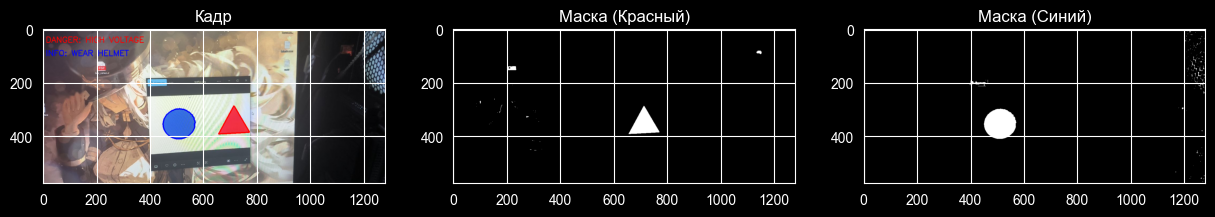

In [3]:
def process_safety_signs(frame):
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

    lower_red1 = np.array([0, 120, 70])
    upper_red1 = np.array([10, 255, 255])
    lower_red2 = np.array([170, 120, 70])
    upper_red2 = np.array([180, 255, 255])

    mask_red1 = cv2.inRange(hsv, lower_red1, upper_red1)
    mask_red2 = cv2.inRange(hsv, lower_red2, upper_red2)
    mask_red = mask_red1 + mask_red2

    lower_blue = np.array([100, 150, 0])
    upper_blue = np.array([140, 255, 255])
    mask_blue = cv2.inRange(hsv, lower_blue, upper_blue)


    kernel = np.ones((5, 5), np.uint8)

    mask_red_clean = cv2.morphologyEx(mask_red, cv2.MORPH_CLOSE, kernel)
    mask_blue_clean = cv2.morphologyEx(mask_blue, cv2.MORPH_CLOSE, kernel)

    def get_center_and_shape(mask, expected_shape):
        contours, _ = cv2.findContours(mask, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
        for cnt in contours:
            if cv2.contourArea(cnt) > 500:
                epsilon = 0.03 * cv2.arcLength(cnt, True)
                approx = cv2.approxPolyDP(cnt, epsilon, True)
                corners = len(approx)

                if (expected_shape == 'triangle' and corners == 3) or \
                   (expected_shape == 'circle' and corners > 6):
                    M = cv2.moments(cnt)
                    if M["m00"] != 0:
                        cx = int(M["m10"] / M["m00"])
                        cy = int(M["m01"] / M["m00"])
                        return (cx, cy), cnt
        return None, None

    triangle_center, tri_cnt = get_center_and_shape(mask_red_clean, 'triangle')
    circle_center, circ_cnt = get_center_and_shape(mask_blue_clean, 'circle')

    if triangle_center:
        cv2.putText(frame, "DANGER: HIGH VOLTAGE", (10, 50), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
        cv2.drawContours(frame, [tri_cnt], 0, (0, 0, 255), 3)

    if circle_center:
        cv2.putText(frame, "INFO: WEAR HELMET", (10, 100), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 2)
        cv2.drawContours(frame, [circ_cnt], 0, (255, 0, 0), 3)

    if triangle_center and circle_center:
        dist = np.sqrt((triangle_center[0] - circle_center[0])**2 + (triangle_center[1] - circle_center[1])**2)
        if dist < 150:
            mode = "MAINTENANCE MODE"
            cv2.putText(frame, mode, (10, 150), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 255, 255), 3)

    return frame, mask_red_clean, mask_blue_clean


frame = cv2.imread('test1.jpg')
processed_frame, m_red, m_blue = process_safety_signs(frame)
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1), plt.title("Кадр"), plt.imshow(cv2.cvtColor(processed_frame, cv2.COLOR_BGR2RGB))
plt.subplot(1, 3, 2), plt.title("Маска (Красный)"), plt.imshow(m_red, cmap='gray')
plt.subplot(1, 3, 3), plt.title("Маска (Синий)"), plt.imshow(m_blue, cmap='gray')

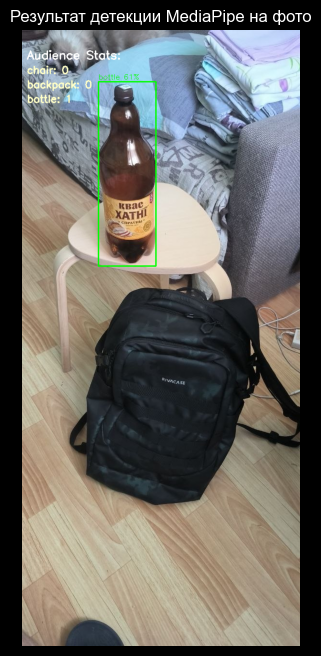

In [18]:

BaseOptions = mp.tasks.BaseOptions
ObjectDetector = mp.tasks.vision.ObjectDetector
ObjectDetectorOptions = mp.tasks.vision.ObjectDetectorOptions
VisionRunningMode = mp.tasks.vision.RunningMode

options = ObjectDetectorOptions(
    base_options=BaseOptions(model_asset_path='efficientdet_lite0.tflite'),
    running_mode=VisionRunningMode.IMAGE,
    max_results=10,
    score_threshold=0.4,
    category_allowlist=['chair', 'backpack', 'bottle']
)
detector = ObjectDetector.create_from_options(options)

def process_audience(frame):

    rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb_frame)

    # Детекция
    detection_result = detector.detect(mp_image)
    counts = {'chair': 0, 'backpack': 0, 'bottle': 0}

    for detection in detection_result.detections:
        category = detection.categories[0].category_name
        if category in counts:
            counts[category] += 1

        bbox = detection.bounding_box
        x, y, w, h = bbox.origin_x, bbox.origin_y, bbox.width, bbox.height
        cv2.rectangle(frame, (x, y), (x + w, y + h), (0, 255, 0), 2)

        score = round(detection.categories[0].score * 100)
        label = f"{category} {score}%"
        cv2.putText(frame, label, (x, y - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)

    y_offset = 60
    cv2.putText(frame, "Audience Stats:", (10, y_offset), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
    for obj, count in counts.items():
        y_offset += 30
        cv2.putText(frame, f"{obj}: {count}", (10, y_offset), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (200, 255, 255), 2)

    return frame

image_path = 'img.png'
test_image = cv2.imread(image_path)

if test_image is not None:
    result_image = process_audience(test_image.copy())
    result_image_rgb = cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 8))
    plt.imshow(result_image_rgb)
    plt.title("Результат детекции MediaPipe на фото")
    plt.axis('off')
    plt.show()

In [11]:
import cv2
import time

def run_realtime():
    cap = cv2.VideoCapture('http://192.168.1.65:4747/video')

    prev_time = time.time()
    fps_smoothed = 0.0

    if not cap.isOpened():
        print("Ошибка: Не удалось открыть веб-камеру.")
        return

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        current_time = time.time()
        time_diff = current_time - prev_time
        if time_diff > 0:
            current_fps = 1.0 / time_diff
            if fps_smoothed == 0.0:
                fps_smoothed = current_fps
            else:
                fps_smoothed = (fps_smoothed * 0.9) + (current_fps * 0.1)
        prev_time = current_time

        processed_frame = process_audience(frame)

        cv2.putText(processed_frame, f"FPS: {int(fps_smoothed)}", (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)

        cv2.imshow('Real-time Analysis', processed_frame)

        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

    cap.release()
    cv2.destroyAllWindows()

run_realtime()